# 01 · EDA, anchor clustering, conversion and ignore-region masking
CPU only. Sections: frame index → annotation statistics → k-means anchors → GT visualisation →
conversion to an Ultralytics dataset with gray-painted ignore regions → visual check of the converted data.
Figures go to `results/figures/`, numbers to `results/eda_stats.json`.

In [1]:
# Paths: auto-detected for Kaggle and for a local clone (data in <repo>/data, outputs in <repo>/outputs).
# Override any of the three variables by hand if your layout differs.
from pathlib import Path
if Path("/kaggle/input").exists():
    DATA_ROOT = next(Path("/kaggle/input").glob("**/test_images.csv")).parent  # competition folder
    REPO_DIR  = Path("/kaggle/working/Video-Detection-HW2")                     # git clone of this repo
    WORK_DIR  = Path("/kaggle/working/outputs")
else:
    REPO_DIR  = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DATA_ROOT = REPO_DIR / "data"
    WORK_DIR  = REPO_DIR / "outputs"
assert (DATA_ROOT / "test_images.csv").exists(), f"test_images.csv not found in {DATA_ROOT}"
print("DATA_ROOT:", DATA_ROOT, "| REPO_DIR:", REPO_DIR, "| WORK_DIR:", WORK_DIR)

DATA_ROOT: /Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2/data | REPO_DIR: /Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2 | WORK_DIR: /Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2/outputs


In [2]:
# Install the pinned dependencies once per session (torch/torchvision are already on Kaggle/Colab).
# !git clone <your-repo-url> {REPO_DIR}
# !pip install -q -r {REPO_DIR}/requirements.txt
# Colab only: keep WORK_DIR on Google Drive so it survives disconnects
# from google.colab import drive; drive.mount("/content/drive")

In [3]:
# Make `src/` importable and print library versions (reproducibility)
import sys
from pathlib import Path
sys.path.insert(0, str(Path(REPO_DIR).resolve()))

from src.utils import load_config, seed_everything, print_versions, detect_env, ensure_dir
print("env:", detect_env())
print_versions()

env: local
python          3.12.6
numpy           2.4.6
torch           2.11.0
torchvision     0.26.0
ultralytics     8.4.208
faster_coco_eval 1.8.0
pycocotools     installed
ensemble_boxes  installed
sahi            0.14.0
cv2             5.0.0
wandb           0.31.0
device          CPU only


In [4]:
# Load the shared config, fix seeds, create output folders
cfg = load_config(Path(REPO_DIR) / "configs" / "base.yaml")
seed_everything(cfg["seed"])

DATA_ROOT, WORK_DIR = Path(DATA_ROOT), ensure_dir(WORK_DIR)
FIG_DIR = ensure_dir(Path(REPO_DIR) / "results" / "figures")
print("train step:", cfg["data"]["train_frame_step"], "| work dir:", WORK_DIR)

train step: 3 | work dir: /Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2/outputs


In [5]:
# Common imports for this notebook
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from src.utils import CLASS_NAMES
from src.dataset import build_frame_index, load_coco_tables, size_bucket, read_yolo_labels, read_ignore
pd.set_option("display.width", 160)
STATS = {}  # numbers collected for the report, saved at the end

## 1. Frame index and clips

In [6]:
# Index every frame of train / val (step=1 here: EDA uses all frames)
idx = {s: build_frame_index(DATA_ROOT / s, frame_step=1) for s in ["train", "val"]}
test_df = pd.read_csv(DATA_ROOT / "test_images.csv")
print("test:", test_df["clip"].nunique(), "clips,", len(test_df), "frames")

[index] train: 56 clips, 24201 frames (step=1)
[index] val: 7 clips, 2846 frames (step=1)
test: 48 clips, 3811 frames


In [7]:
# Per-clip summary: number of frames and resolution, for each split
clips = pd.concat([d.assign(split=s) for s, d in idx.items()] +
                  [test_df.assign(split="test")[["clip", "width", "height", "split"]]])
clip_summary = (clips.groupby(["split", "clip"]).agg(frames=("clip", "size"), width=("width", "first"),
                                                     height=("height", "first")).reset_index())
res_counts = clip_summary.groupby(["split", "width", "height"]).size().unstack(0, fill_value=0)
STATS["resolutions"] = {f"{w}x{h}": row.to_dict() for (w, h), row in res_counts.iterrows()}
res_counts

split         test  train  val
width height                  
680   382        3      0    0
960   540        5      0    0
1344  756        7     11    2
1360  764       18      0    0
      765        0      1    0
1904  1071       0     30    2
      1072       4      0    0
1920  1080      11      1    0
2688  1512       0     11    1
2720  1530       0      2    1
3840  2160       0      0    1

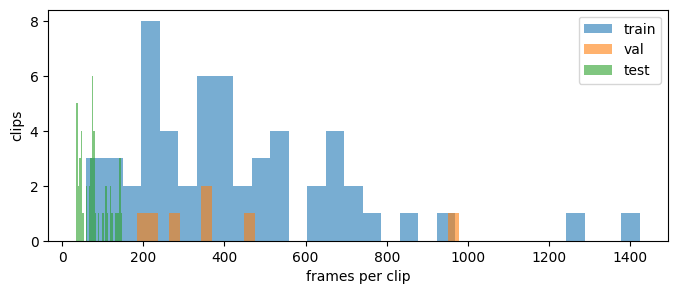

In [8]:
# Frames per clip (train/val/test): short vs long clips matter for frame subsampling
fig, ax = plt.subplots(figsize=(8, 3))
for s in ["train", "val", "test"]:
    ax.hist(clip_summary.query("split == @s")["frames"], bins=30, alpha=0.6, label=s)
ax.set_xlabel("frames per clip"); ax.set_ylabel("clips"); ax.legend()
fig.savefig(FIG_DIR / "eda_frames_per_clip.png", dpi=120, bbox_inches="tight"); plt.show()

## 2. Annotations (from `annotations_coco.json`)

In [9]:
# Load COCO json -> DataFrames; split real objects and ignore regions (iscrowd = 1)
tables = {s: load_coco_tables(DATA_ROOT / s / "annotations_coco.json") for s in ["train", "val"]}
objs = {s: a[a["iscrowd"] == 0].copy() for s, (_, a) in tables.items()}
igns = {s: a[a["iscrowd"] == 1].copy() for s, (_, a) in tables.items()}
for s in objs:
    print(f"{s}: images={len(tables[s][0])} objects={len(objs[s])} ignore_regions={len(igns[s])}")
print("annotation columns:", list(objs["train"].columns))
print("first image entry:", tables["train"][0].iloc[0].to_dict())

train: images=24201 objects=1105516 ignore_regions=510744
val: images=2846 objects=114132 ignore_regions=31960
annotation columns: ['id', 'image_id', 'category_id', 'area', 'iscrowd', 'truncation', 'occlusion', 'track_id', 'orig_category_id', 'ignore', 'x', 'y', 'w', 'h', 'area_px', 'size', 'cls', 'class', 'clip', 'key', 'width', 'height']
first image entry: {'id': 1, 'file_name': 'images/uav0000013_00000_v/0000001.jpg', 'width': 1344, 'height': 756, 'video_id': 1, 'video': 'uav0000013_00000_v', 'frame_id': 1, 'clip': 'uav0000013_00000_v', 'key': 'uav0000013_00000_v_0000001'}


In [10]:
# Cross-check: YOLO txt labels and COCO json must agree (counts per class on 50 random frames)
rng = np.random.default_rng(cfg["seed"])
sample = idx["train"].sample(50, random_state=cfg["seed"])
yolo_cls = np.concatenate([read_yolo_labels(r.label_path, r.width, r.height)[1] for r in sample.itertuples()])
coco_cls = objs["train"][objs["train"]["key"].isin(sample["key"])]["cls"].to_numpy()
cmp = pd.DataFrame({"yolo": np.bincount(yolo_cls, minlength=8), "coco": np.bincount(coco_cls, minlength=8)},
                   index=CLASS_NAMES)
print("match:", (cmp["yolo"] == cmp["coco"]).all()); cmp.T

match: True


,person,bicycle,car,van,truck,tricycle,bus,motor
yolo,719,125,1308,105,63,69,23,205
coco,719,125,1308,105,63,69,23,205


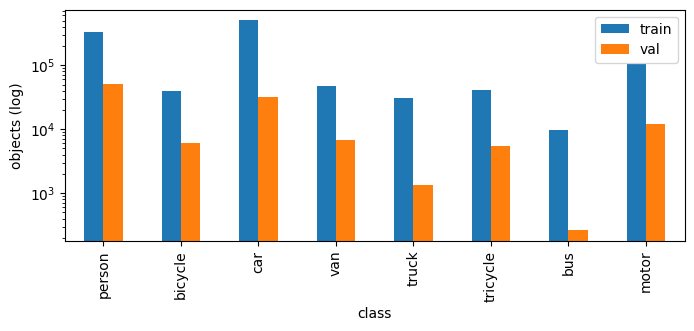

,train,val,train_%
class,,,
person,328701,50312,29.73
bicycle,40255,6022,3.64
car,505301,31821,45.71
van,46940,6842,4.25
truck,30498,1359,2.76
tricycle,41349,5487,3.74
bus,9653,264,0.87
motor,102819,12025,9.30


In [11]:
# Class distribution, train vs val (log scale: strong imbalance expected)
dist = pd.DataFrame({s: objs[s]["class"].value_counts().reindex(CLASS_NAMES) for s in objs})
dist["train_%"] = (100 * dist["train"] / dist["train"].sum()).round(2)
STATS["class_counts"] = dist[["train", "val"]].to_dict()
ax = dist[["train", "val"]].plot.bar(figsize=(8, 3), logy=True); ax.set_ylabel("objects (log)")
plt.savefig(FIG_DIR / "eda_class_distribution.png", dpi=120, bbox_inches="tight"); plt.show()
dist

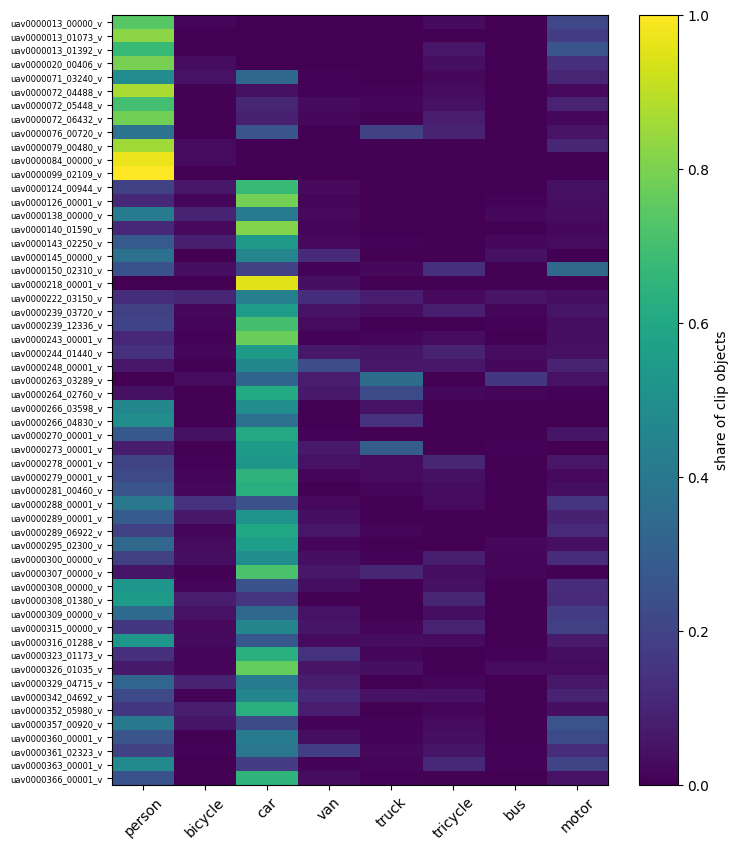

clips without any instance of a class (train): {'person': 1, 'bicycle': 15, 'car': 7, 'van': 10, 'truck': 17, 'tricycle': 17, 'bus': 32, 'motor': 6}


In [12]:
# Class share per clip (train): shows how much scene content varies between clips
per_clip = pd.crosstab(objs["train"]["clip"], objs["train"]["class"], normalize="index")[CLASS_NAMES]
fig, ax = plt.subplots(figsize=(8, 10))
im = ax.imshow(per_clip.values, aspect="auto", cmap="viridis")
ax.set_xticks(range(8)); ax.set_xticklabels(CLASS_NAMES, rotation=45)
ax.set_yticks(range(len(per_clip))); ax.set_yticklabels(per_clip.index, fontsize=6)
plt.colorbar(im, label="share of clip objects")
plt.savefig(FIG_DIR / "eda_class_per_clip.png", dpi=120, bbox_inches="tight"); plt.show()
print("clips without any instance of a class (train):", (per_clip == 0).sum().to_dict())

## 3. Object sizes

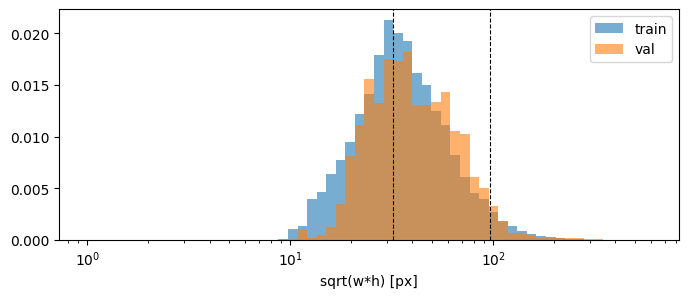

size percentiles (train): {0.05: 19.7, 0.25: 32.0, 0.5: 45.8, 0.75: 67.9, 0.95: 130.2}


,train,val
area_px,,
medium,0.635,0.695
small,0.249,0.192
large,0.116,0.113


In [13]:
# Object size = sqrt(w*h) in original pixels; COCO small/medium/large shares
fig, ax = plt.subplots(figsize=(8, 3))
bins = np.logspace(0, np.log10(600), 60)
for s in objs:
    ax.hist(objs[s]["size"], bins=bins, alpha=0.6, density=True, label=s)
for t in (32, 96):
    ax.axvline(t, color="k", ls="--", lw=0.8)
ax.set_xscale("log"); ax.set_xlabel("sqrt(w*h) [px]"); ax.legend()
plt.savefig(FIG_DIR / "eda_object_size.png", dpi=120, bbox_inches="tight"); plt.show()

buckets = pd.DataFrame({s: size_bucket(objs[s]["area_px"]).value_counts(normalize=True) for s in objs}).round(3)
STATS["size_buckets"] = buckets.to_dict()
STATS["size_percentiles_train"] = objs["train"]["size"].quantile([.05, .25, .5, .75, .95]).round(1).to_dict()
print("size percentiles (train):", STATS["size_percentiles_train"]); buckets

In [14]:
# Size per class and aspect ratio h/w per class (train)
o = objs["train"]
per_cls = o.groupby("class").agg(median_size=("size", "median"),
                                 p10_size=("size", lambda x: x.quantile(.1))).reindex(CLASS_NAMES)
per_cls["median_h_over_w"] = (o["h"] / o["w"].clip(lower=1)).groupby(o["class"]).median().reindex(CLASS_NAMES)
per_cls["small_%"] = (100 * (o["area_px"] < 32**2).groupby(o["class"]).mean()).reindex(CLASS_NAMES).round(1)
STATS["per_class_size"] = per_cls.round(2).to_dict()
per_cls.round(2)

,median_size,p10_size,median_h_over_w,small_%
class,,,,
person,35.78,19.80,2.00,39.5
bicycle,41.41,24.90,1.06,24.4
car,57.01,28.27,0.80,16.3
van,49.85,28.14,0.90,21.4
truck,73.46,32.73,0.93,9.4
tricycle,54.85,24.25,0.94,21.0
bus,113.45,41.83,0.97,4.1
motor,40.21,20.20,1.24,30.4


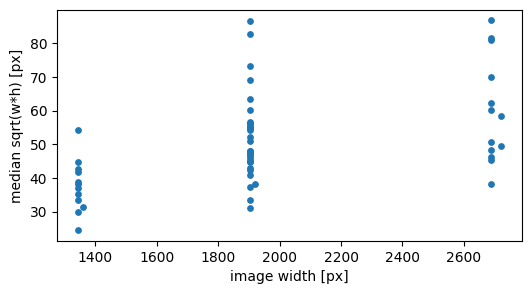

median size per clip: min 24.5 / median 47.7 / max 86.8


In [15]:
# Median object size per clip vs. image width: does object scale depend on resolution / altitude?
g = objs["train"].groupby("clip").agg(median_size=("size", "median"), width=("width", "first"))
fig, ax = plt.subplots(figsize=(6, 3))
ax.scatter(g["width"], g["median_size"], s=15)
ax.set_xlabel("image width [px]"); ax.set_ylabel("median sqrt(w*h) [px]")
plt.savefig(FIG_DIR / "eda_size_vs_resolution.png", dpi=120, bbox_inches="tight"); plt.show()
print("median size per clip: min %.1f / median %.1f / max %.1f" % tuple(g["median_size"].quantile([0, .5, 1])))

## 4. Objects per frame

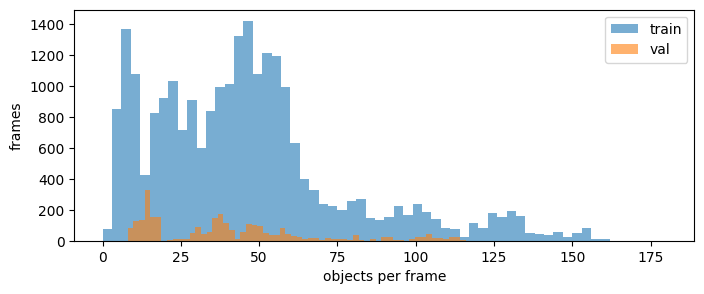

,train,val
mean,45.7,40.1
p95,118.0,103.0
p99,142.0,112.0
max,180.0,116.0
frames_over_300,0.0,0.0
frames_over_500,0.0,0.0


In [16]:
# Objects per frame: drives max_det (500 cap) and the number of DETR queries (300 default)
fig, ax = plt.subplots(figsize=(8, 3))
STATS["objects_per_frame"] = {}
for s, (imgs, _) in tables.items():
    counts = objs[s].groupby("image_id").size().reindex(imgs["id"], fill_value=0)
    ax.hist(counts, bins=60, alpha=0.6, label=s)
    STATS["objects_per_frame"][s] = {"mean": round(counts.mean(), 1), "p95": int(counts.quantile(.95)),
                                     "p99": int(counts.quantile(.99)), "max": int(counts.max()),
                                     "frames_over_300": int((counts > 300).sum()),
                                     "frames_over_500": int((counts > 500).sum())}
ax.set_xlabel("objects per frame"); ax.set_ylabel("frames"); ax.legend()
plt.savefig(FIG_DIR / "eda_objects_per_frame.png", dpi=120, bbox_inches="tight"); plt.show()
pd.DataFrame(STATS["objects_per_frame"])

## 5. Occlusion / truncation

In [17]:
# VisDrone occlusion: 0 none, 1 partial (1-50%), 2 heavy (50-100%); truncation: 0 none, 1 partial
cols = [c for c in ["occlusion", "truncation"] if c in objs["train"]]
occ = {c: pd.crosstab(objs["train"]["class"], objs["train"][c], normalize="index").reindex(CLASS_NAMES).round(3)
       for c in cols}
for c, t in occ.items():
    STATS[f"{c}_share_by_class"] = t.to_dict()
    print(f"--- {c} (share per class, train)"); display(t)

--- occlusion (share per class, train)


occlusion,0.0,1.0,2.0
class,,,
person,0.541,0.396,0.063
bicycle,0.465,0.501,0.034
car,0.570,0.384,0.046
van,0.571,0.404,0.025
truck,0.353,0.489,0.158
tricycle,0.409,0.570,0.021
bus,0.559,0.420,0.021
motor,0.547,0.390,0.063


--- truncation (share per class, train)


truncation,0.0,1.0
class,,
person,0.980,0.020
bicycle,0.992,0.008
car,0.943,0.057
van,0.958,0.042
truck,0.888,0.112
tricycle,0.954,0.046
bus,0.862,0.138
motor,0.969,0.031


## 6. Ignore regions

In [18]:
# How often frames contain ignore regions and how much of the frame they cover
STATS["ignore"] = {}
for s, (imgs, _) in tables.items():
    ig = igns[s].assign(frac=igns[s]["area_px"] / (igns[s]["width"] * igns[s]["height"]))
    per_img = ig.groupby("image_id")["frac"].sum().clip(upper=1)   # upper bound: overlaps counted twice
    STATS["ignore"][s] = {"frames_with_ignore_%": round(100 * len(per_img) / len(imgs), 1),
                          "regions_per_frame_mean": round(len(ig) / len(imgs), 2),
                          "covered_area_%_mean_when_present": round(100 * per_img.mean(), 2),
                          "covered_area_%_max": round(100 * per_img.max(), 2)}
print("ignore category ids in json:", sorted(igns["train"]["category_id"].unique()))
pd.DataFrame(STATS["ignore"])

ignore category ids in json: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


,train,val
frames_with_ignore_%,74.70,50.40
regions_per_frame_mean,21.10,11.23
covered_area_%_mean_when_present,23.64,25.65
covered_area_%_max,100.00,88.56


## 7. K-means anchors (YOLOv2 dimension clusters, 1-IoU distance)

In [19]:
# Cluster GT (w, h) in ORIGINAL pixels. k=9 (3 per level, YOLO-style) and k=5 (1 size per FPN level P3-P7)
from src.anchors import kmeans_anchors, anchors_to_sizes_ratios
wh = objs["train"][["w", "h"]].to_numpy()
anchor_res = {}
for k in (5, 9):
    cent, miou = kmeans_anchors(wh, k=k, seed=cfg["seed"])
    sizes, ratios = anchors_to_sizes_ratios(cent)
    anchor_res[k] = {"wh": cent.round(1).tolist(), "sizes": sizes.round(1).tolist(),
                     "ratios_h_over_w": ratios.round(2).tolist(), "mean_iou": round(miou, 3)}
    print(f"k={k}  mean IoU={miou:.3f}\n  sizes={sizes.round(1)}\n  h/w ={ratios.round(2)}")
STATS["kmeans_anchors"] = anchor_res

k=5  mean IoU=0.656
  sizes=[       24.1        41.4          42        70.3       128.8]
  h/w =[       1.45        0.71        1.84        0.86        0.69]
k=9  mean IoU=0.725
  sizes=[       16.7        24.7          30        36.1          45        47.4        59.8        75.3       138.3]
  h/w =[       1.43        2.12        0.94        2.08        1.05        0.52        1.62        0.66        0.73]


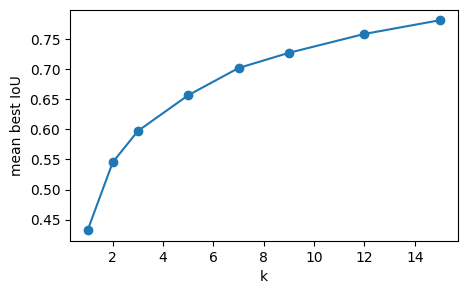

In [20]:
# Mean IoU vs k (elbow plot) to justify the number of anchors
ks = [1, 2, 3, 5, 7, 9, 12, 15]
mious = [kmeans_anchors(wh, k=k, seed=cfg["seed"], max_samples=50_000)[1] for k in ks]
fig, ax = plt.subplots(figsize=(5, 3)); ax.plot(ks, mious, "o-")
ax.set_xlabel("k"); ax.set_ylabel("mean best IoU")
plt.savefig(FIG_DIR / "eda_kmeans_elbow.png", dpi=120, bbox_inches="tight"); plt.show()

In [21]:
# Default torchvision anchors (32..512, ratios 0.5/1/2) vs. the GT: share of boxes with best IoU < 0.5
from src.anchors import wh_iou
default = np.array([[s * np.sqrt(1 / r), s * np.sqrt(r)] for s in (32, 64, 128, 256, 512) for r in (0.5, 1, 2)])
kmeans9 = np.array(anchor_res[9]["wh"])
sub = wh[np.random.default_rng(0).choice(len(wh), min(100_000, len(wh)), replace=False)]
for name, a in [("torchvision default", default), ("k-means k=9", kmeans9)]:
    best = wh_iou(sub, a).max(1)
    print(f"{name:20s} mean IoU={best.mean():.3f}  boxes with IoU<0.5: {100 * (best < .5).mean():.1f}%")

torchvision default  mean IoU=0.672  boxes with IoU<0.5: 8.5%
k-means k=9          mean IoU=0.724  boxes with IoU<0.5: 3.1%


In [22]:
# OBSERVATIONS -> design decisions (fill the numbers from the outputs above; keep as comments)
# - Object size: check STATS["size_buckets"]; if most objects are "small" (<32 px) ->
#   use a large imgsz (>= 960/1280) or tiles at native resolution, and add a P2 (stride-4) head.
# - Anchors: compare the k-means sizes with torchvision defaults (32..512) ->
#   smaller anchor sizes (e.g. 8/16/32/64/128) for RetinaNet / Faster R-CNN RPN.
# - Objects per frame: check p99 / max / frames_over_300 -> max_det=500 at inference and
#   num_queries > 300 for RT-DETR if many frames exceed 300 objects.
# - Class imbalance (dist): rare classes (e.g. tricycle/bus/bicycle) -> look at per-class AP,
#   consider class-balanced sampling only if their AP is very low.
# - Resolution varies per clip -> no fixed resize per clip; letterbox/scale jitter in training.
# - Ignore regions: share of frames and covered area -> justifies masking them in training.

In [23]:
# Save all collected numbers (used later to write the report by hand)
with open(Path(REPO_DIR) / "results" / "eda_stats.json", "w") as f:
    json.dump(STATS, f, indent=1, default=str)
print("saved", list(STATS))

saved ['resolutions', 'class_counts', 'size_buckets', 'size_percentiles_train', 'per_class_size', 'objects_per_frame', 'occlusion_share_by_class', 'truncation_share_by_class', 'ignore', 'kmeans_anchors']


## 8. GT visualisation (verifies the YOLO ↔ COCO conversion)

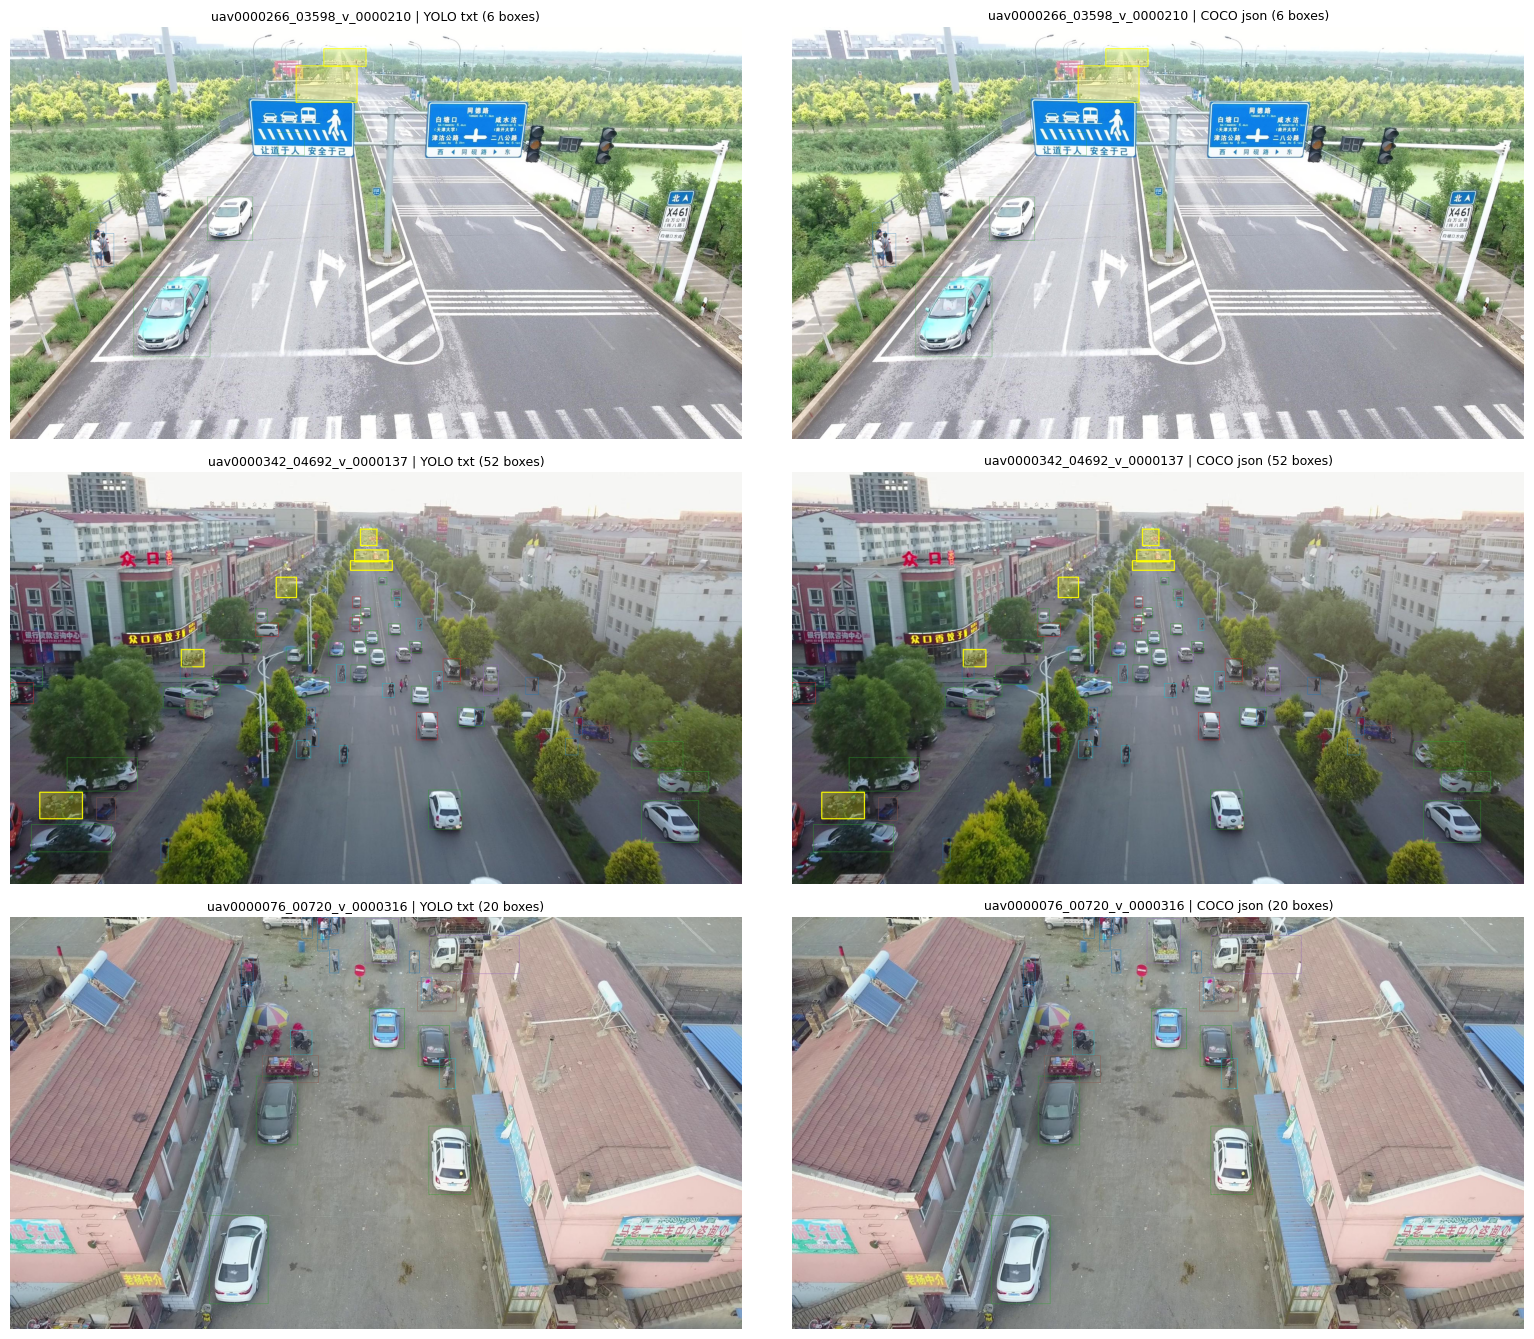

In [24]:
# Left: boxes from YOLO txt + ignore txt. Right: boxes from COCO json (iscrowd=1 in yellow). Must be identical.
from src.viz import draw_boxes, show_grid, legend_handles
from src.utils import xywh_to_xyxy
frames = idx["train"].sample(3, random_state=1)
ims, titles = [], []
for r in frames.itertuples():
    img = cv2.imread(r.img_path)
    b, c = read_yolo_labels(r.label_path, r.width, r.height)
    ims.append(draw_boxes(img, b, c, ignore_xyxy=read_ignore(r.ignore_path, r.width, r.height)))
    a = tables["train"][1].query("key == @r.key")
    real, crowd = a[a.iscrowd == 0], a[a.iscrowd == 1]
    ims.append(draw_boxes(img, xywh_to_xyxy(real[["x", "y", "w", "h"]].to_numpy()), real["cls"].to_numpy(),
                          ignore_xyxy=xywh_to_xyxy(crowd[["x", "y", "w", "h"]].to_numpy())))
    titles += [f"{r.key} | YOLO txt ({len(b)} boxes)", f"{r.key} | COCO json ({len(real)} boxes)"]
show_grid(ims, titles, ncols=2, save_path=FIG_DIR / "eda_gt_yolo_vs_coco.png")

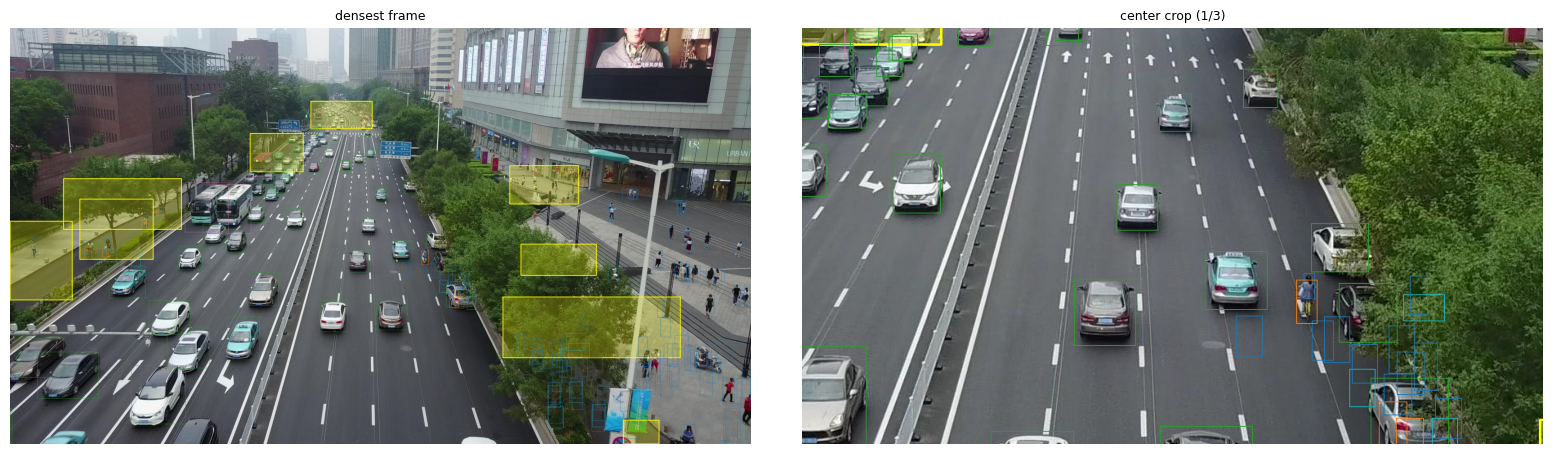

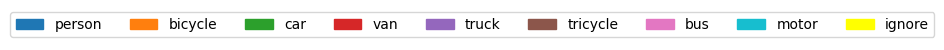

In [25]:
# Zoom on a crowded frame (most objects) to see how small / dense the objects are
r = idx["train"].set_index("key").loc[objs["train"]["key"].value_counts().index[0]]
img = cv2.imread(r.img_path)
b, c = read_yolo_labels(r.label_path, r.width, r.height)
vis = draw_boxes(img, b, c, ignore_xyxy=read_ignore(r.ignore_path, r.width, r.height))
h, w = vis.shape[:2]
show_grid([vis, vis[h // 3: 2 * h // 3, w // 3: 2 * w // 3]], ["densest frame", "center crop (1/3)"],
          save_path=FIG_DIR / "eda_densest_frame.png")
plt.figure(figsize=(6, 0.4)); plt.axis("off"); plt.legend(handles=legend_handles(), ncol=9, loc="center"); plt.show()

## 9. Conversion → Ultralytics dataset with masked ignore regions
Train uses `cfg.data.train_frame_step` (default 3); val uses every frame. Ignore regions are painted gray (114) on copies,
GT boxes covered > 50 % are dropped, kept boxes are restored (see `src/convert.py`). Re-running reuses finished splits.
Approx. time: 10-25 min on Kaggle CPU for step 3; disk ≈ size of masked frames only (others are symlinks).

In [26]:
# Build the Ultralytics splits + data.yaml under WORK_DIR/yolo
from src.convert import build_yolo_split, write_data_yaml
RUN_CONVERSION = True          # set False to skip if WORK_DIR/yolo is already built
BUILD_STEP1_ABLATION = False   # also build train with step 1 for the step-1 vs step-3 ablation
d = cfg["data"]
YOLO_ROOT = ensure_dir(WORK_DIR / "yolo")
step = d["train_frame_step"]
kw = dict(fill=d["ignore_fill"], drop_ioa=d["ignore_drop_ioa"], link_unmasked=d["link_unmasked"])
if RUN_CONVERSION:
    tr_dir = build_yolo_split(build_frame_index(DATA_ROOT / "train", step), YOLO_ROOT, f"train_step{step}", **kw)
    va_dir = build_yolo_split(build_frame_index(DATA_ROOT / "val", d["val_frame_step"]), YOLO_ROOT, "val", **kw)
    write_data_yaml(YOLO_ROOT / f"data_step{step}.yaml", [tr_dir], va_dir)
    write_data_yaml(YOLO_ROOT / f"data_trainval_step{step}.yaml", [tr_dir, va_dir], va_dir)  # final fit
    if BUILD_STEP1_ABLATION and step != 1:
        tr1 = build_yolo_split(build_frame_index(DATA_ROOT / "train", 1), YOLO_ROOT, "train_step1", **kw)
        write_data_yaml(YOLO_ROOT / "data_step1.yaml", [tr1], va_dir)

[index] train: 56 clips, 8090 frames (step=3)


convert train_step3:   0%|          | 0/8090 [00:00<?, ?it/s]

[convert] train_step3: frames=8090 masked_frames=6053 boxes_kept=365903 boxes_dropped_in_ignore=4169
[index] val: 7 clips, 2846 frames (step=1)


convert val:   0%|          | 0/2846 [00:00<?, ?it/s]

[convert] val: frames=2846 masked_frames=1434 boxes_kept=112935 boxes_dropped_in_ignore=1197
[convert] wrote /Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2/outputs/yolo/data_step3.yaml
[convert] wrote /Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2/outputs/yolo/data_trainval_step3.yaml


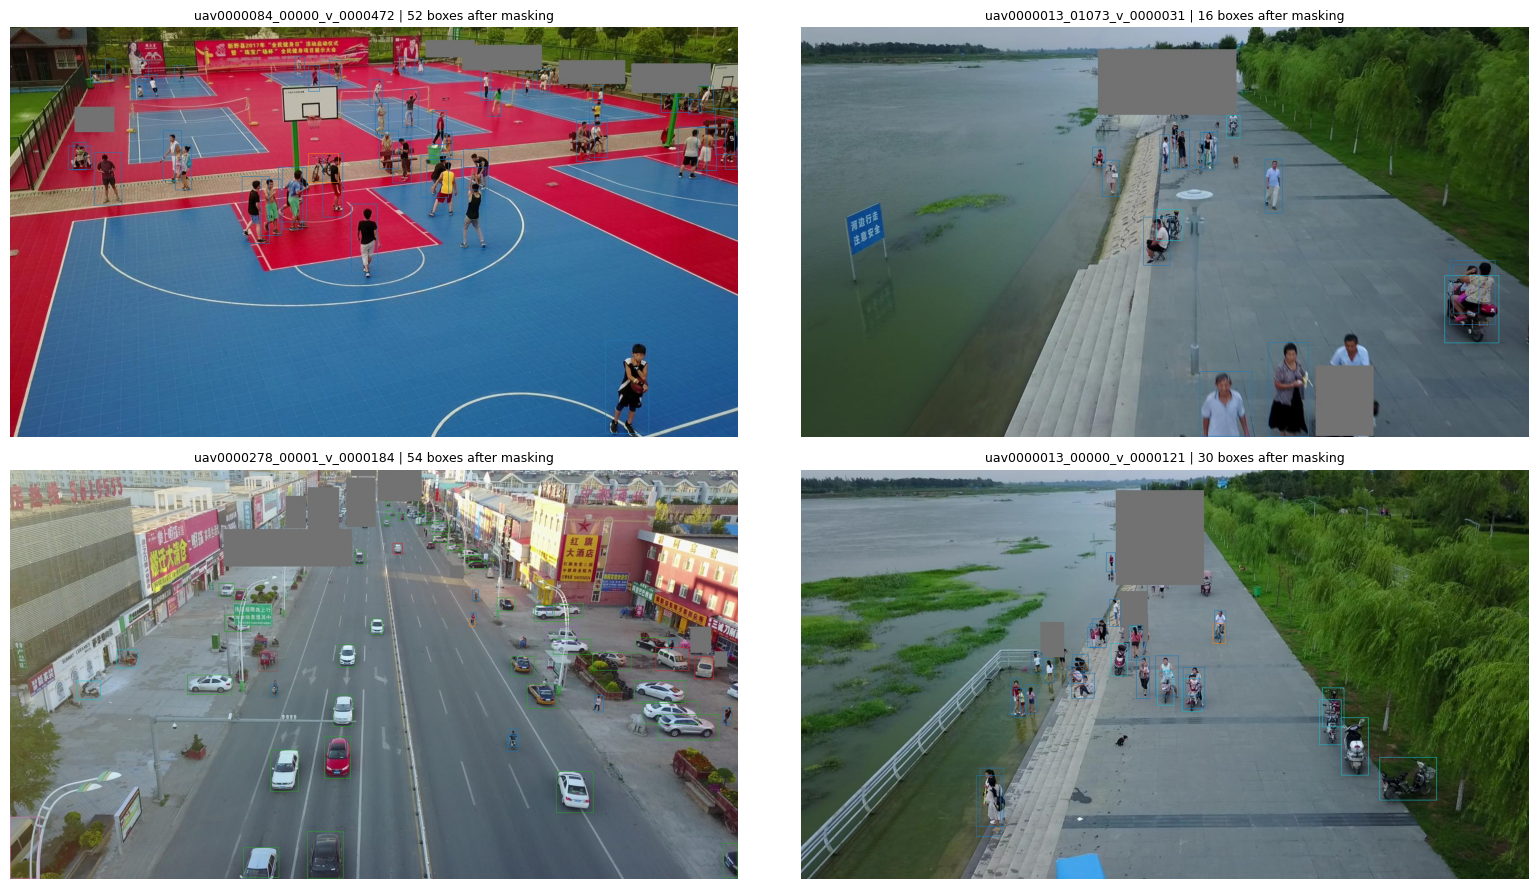

{'path': '/Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2/outputs/yolo', 'train': ['/Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2/outputs/yolo/train_step3/images'], 'val': '/Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2/outputs/yolo/val/images', 'nc': 8, 'names': {0: 'person', 1: 'bicycle', 2: 'car', 3: 'van', 4: 'truck', 5: 'tricycle', 6: 'bus', 7: 'motor'}}


In [27]:
# Visual check of the CONVERTED data: masked frames (gray ignore areas) with the rewritten YOLO labels
import yaml
from src.utils import yolo_to_xyxy
conv_dir = YOLO_ROOT / f"train_step{step}"
masked = [p for p in (conv_dir / "images").glob("*.jpg") if not p.is_symlink()][:200]
picks = np.random.default_rng(cfg["seed"]).choice(masked, size=min(4, len(masked)), replace=False)
ims, titles = [], []
for p in picks:
    img = cv2.imread(str(p)); H, W = img.shape[:2]
    lab = np.loadtxt(conv_dir / "labels" / f"{p.stem}.txt", ndmin=2)
    b = yolo_to_xyxy(lab[:, 1:5], W, H) if len(lab) else np.zeros((0, 4))
    ims.append(draw_boxes(img, b, lab[:, 0].astype(int) if len(lab) else []))
    titles.append(f"{p.stem} | {len(b)} boxes after masking")
show_grid(ims, titles, ncols=2, save_path=FIG_DIR / "eda_masked_training_frames.png")
print(yaml.safe_load(open(YOLO_ROOT / f"data_step{step}.yaml")))